# чат и динамика матча

к базовой модели добавляются текст, статистики временных рядов и тренды.

в исходном запуске gini вырос с 0,31101 до 0,41736. выбраны тренды, текст и временные окна. ниже — локальный повторный запуск.

In [1]:
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
import sys
project_root = next((path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src' / 'dota_project').is_dir()))
sys.path.insert(0, str(project_root / 'src'))
from dota_project.paths import data_path, output_path
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)


## данные и базовая модель

baseline собирается заново с теми же правилами очистки и разделением по времени. так этот ноутбук можно запустить отдельно.

In [2]:
from pathlib import Path
import json
import re
import time
import uuid
import sys
import subprocess
import importlib.util
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.tokenize import TweetTokenizer
SEED = 42
OUTPUT = output_path(project_root, 'advanced')
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True})
data_dir = data_path(project_root)
train_path = data_dir / 'matches_df_train.csv'
train = pd.read_csv(train_path)
test = pd.read_csv(data_dir / 'matches_df_test.csv')
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])
from sklearn.metrics import roc_auc_score

def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1.0
date_columns = ['day_sin', 'day_cos', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos', 'weekend']
for df in [train, test]:
    date = df['date']
    df['day_sin'] = np.sin(2 * np.pi * (date.dt.day - 1) / date.dt.days_in_month)
    df['day_cos'] = np.cos(2 * np.pi * (date.dt.day - 1) / date.dt.days_in_month)
    df['weekday_sin'] = np.sin(2 * np.pi * date.dt.dayofweek / 7)
    df['weekday_cos'] = np.cos(2 * np.pi * date.dt.dayofweek / 7)
    df['month_sin'] = np.sin(2 * np.pi * (date.dt.month - 1) / 12)
    df['month_cos'] = np.cos(2 * np.pi * (date.dt.month - 1) / 12)
    df['weekend'] = (date.dt.dayofweek >= 5).astype(int)
display(train[['date'] + date_columns].head())
cutoff = train['date'].max().to_period('M').start_time
fit_df = train.loc[train['date'] < cutoff].copy()
valid_df = train.loc[train['date'] >= cutoff].copy()
assert fit_df['date'].max() < valid_df['date'].min()
print('граница oot:', cutoff)
print('train:', fit_df.shape, 'valid:', valid_df.shape)
results = []
models = {}

def make_model(use_dates=False, mmr=None, params=None):
    blocks = [('region', OneHotEncoder(handle_unknown='ignore'), ['region'])]
    if use_dates:
        blocks.append(('dates', StandardScaler(), date_columns))
    if mmr is not None:
        transform = np.log1p if mmr == 'log' else None
        steps = [('impute', SimpleImputer(strategy='median', add_indicator=True))]
        if transform is not None:
            steps = [('log', FunctionTransformer(np.log1p)), ('impute', SimpleImputer(strategy='median', add_indicator=True))]
        steps.append(('scale', StandardScaler()))
        blocks.append(('mmr', Pipeline(steps), ['avg_mmr']))
    settings = dict(C=1.0, solver='lbfgs', max_iter=500, random_state=42)
    settings.update(params or {})
    return Pipeline([('features', ColumnTransformer(blocks)), ('model', LogisticRegression(**settings))])


,date,day_sin,day_cos,weekday_sin,weekday_cos,month_sin,month_cos,weekend
0,2024-02-12,6.876995e-01,-0.725995,0.000000,1.00000,0.500000,8.660254e-01,0
1,2024-04-08,9.945219e-01,0.104528,0.000000,1.00000,1.000000,6.123234e-17,0
2,2024-06-16,5.665539e-16,-1.000000,-0.781831,0.62349,0.500000,-8.660254e-01,1
3,2024-09-16,5.665539e-16,-1.000000,0.000000,1.00000,-0.866025,-5.000000e-01,0
4,2024-03-31,-2.012985e-01,0.979530,-0.781831,0.62349,0.866025,5.000000e-01,1


граница oot: 2024-11-01 00:00:00
train: (582297, 14) valid: (58793, 14)


ниже сравниваются доли пропусков в статистике игроков для train и test.

In [3]:
def evaluate_model(name, model, train_data, valid_data):
    model.fit(train_data, train_data['radiant_win'])
    row = {'model': name, 'gini_train': gini(train_data['radiant_win'], model.predict_proba(train_data)[:, 1]), 'gini_valid': gini(valid_data['radiant_win'], model.predict_proba(valid_data)[:, 1])}
    results.append(row)
    models[name] = model
    return row
data_dir = train_path.parent
player_raw = pd.read_csv(data_dir / 'player_df.csv')
heroes = pd.read_csv(data_dir / 'Constants.Heroes.csv')
display(player_raw.head())
display(player_raw['account_id'].value_counts().head(15))
suspicious_ids = [-1, 4294967295]
for account in suspicious_ids:
    affected = player_raw.loc[player_raw['account_id'].eq(account), 'match_id'].nunique()
    print(account, 'матчей:', affected, 'доля:', affected / player_raw['match_id'].nunique())
display(pd.DataFrame({name: player_raw.loc[player_raw['match_id'].isin(df['match_id'])].isna().mean() for name, df in [('train', train), ('test', test)]}))
player_df = player_raw[['match_id', 'player_slot', 'account_id', 'hero_id']].copy()
del player_raw
duplicate_hero_ids = player_df.loc[player_df.duplicated(['match_id', 'hero_id'], keep=False), 'match_id'].unique()
print('матчей с повторными героями:', len(duplicate_hero_ids))
bad_match_ids = set(duplicate_hero_ids)
display(player_df.loc[player_df['hero_id'].eq(0), 'account_id'].value_counts())
relevant_ids = pd.Index(pd.concat([train['match_id'], test['match_id']]))
player_df = player_df.loc[player_df['match_id'].isin(relevant_ids)].copy()
invalid_row = player_df.isna().any(axis=1) | ~player_df['hero_id'].isin(heroes['id']) | (player_df['account_id'] < 0)
bad_match_ids.update(player_df.loc[invalid_row, 'match_id'])
valid_slots = list(range(5)) + list(range(128, 133))
bad_match_ids.update(player_df.loc[~player_df['player_slot'].isin(valid_slots), 'match_id'])
player_df['team'] = (player_df['player_slot'] >= 128).astype('int8')
public_players = player_df.loc[~player_df['account_id'].isin(suspicious_ids)]
cross_team = public_players.groupby(['match_id', 'account_id'])['team'].nunique()
bad_match_ids.update(cross_team[cross_team > 1].index.get_level_values('match_id'))
slot_counts = player_df.groupby('match_id')['player_slot'].agg(['size', 'nunique'])
team_counts = player_df.groupby(['match_id', 'team']).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
invalid_count = slot_counts['size'].ne(10) | slot_counts['nunique'].ne(10) | team_counts[0].ne(5) | team_counts[1].ne(5)
bad_match_ids.update(slot_counts.index[invalid_count])
player_df = player_df.loc[~player_df['match_id'].isin(bad_match_ids)].copy()
clean_ids = pd.Index(player_df['match_id'].unique())
train_clean = train.loc[train['match_id'].isin(clean_ids)].copy()
fit_clean = train_clean.loc[train_clean['date'] < cutoff].copy()
valid_clean = train_clean.loc[train_clean['date'] >= cutoff].copy()
assert player_df.groupby('match_id')['hero_id'].nunique().eq(10).all()
assert player_df.groupby(['match_id', 'team']).size().eq(5).all()
assert player_df.groupby('match_id')['player_slot'].nunique().eq(10).all()
assert not player_df.isna().any().any()
print('удалено train:', len(train) - len(train_clean))
print('test без корректных составов:', (~test['match_id'].isin(clean_ids)).sum())
print('чистые выборки:', fit_clean.shape, valid_clean.shape)

class HeroesEncoder(BaseEstimator, TransformerMixin):

    def __init__(self, players, hero_ids):
        self.players = players
        self.hero_ids = hero_ids

    def fit(self, X, y=None):
        self.hero_index_ = pd.Index(self.hero_ids)
        self.match_index_ = pd.Index(self.players['match_id'].unique())
        rows = self.match_index_.get_indexer(self.players['match_id'])
        cols = self.hero_index_.get_indexer(self.players['hero_id'])
        assert (cols >= 0).all()
        values = np.where(self.players['player_slot'] < 128, 1, -1).astype(np.float64)
        self.matrix_ = sparse.csr_matrix((values, (rows, cols)), shape=(len(self.match_index_), len(self.hero_index_)))
        return self

    def transform(self, X):
        ids = np.asarray(X).reshape(-1)
        positions = self.match_index_.get_indexer(ids)
        if (positions < 0).any():
            raise ValueError('нет корректного состава для части матчей')
        return self.matrix_[positions]


,player_slot,account_id,hero_id,kills,deaths,assists,gold,last_hits,denies,gold_per_min,xp_per_min,hero_damage,tower_damage,match_id
0,130,10111871,5,3.0,8.0,15.0,2971.0,55.0,3.0,291.0,390.0,7431.0,146.0,215380
1,130,43341844,3,3.0,9.0,3.0,1245.0,25.0,3.0,238.0,346.0,4187.0,34.0,185234
2,130,72157343,53,9.0,6.0,20.0,4544.0,226.0,1.0,583.0,704.0,9406.0,2375.0,573078
3,1,4294967295,17,21.0,3.0,15.0,2945.0,209.0,12.0,577.0,641.0,30957.0,1801.0,366576
4,2,54350942,19,9.0,8.0,8.0,413.0,227.0,9.0,471.0,584.0,18215.0,627.0,455795


account_id
 4294967295    2795673
-1               27267
 37619671          801
 84244723          763
 87266522          761
 38584608          752
 85427446          743
 62933415          742
 151993649         740
 137331734         735
 64800968          713
 49092801          707
 198434112         705
 10856368          702
 13934403          695
Name: count, dtype: int64

-1 матчей: 5436 доля: 0.007079765883238563
4294967295 матчей: 696986 доля: 0.9077442428062754


,train,test
player_slot,0.000000,0.000000
account_id,0.000000,0.000000
hero_id,0.000000,0.000000
kills,0.000002,0.999983
deaths,0.000002,0.999983
assists,0.000002,0.999983
gold,0.000002,0.999983
last_hits,0.000002,0.999983
denies,0.000002,0.999983
gold_per_min,0.000002,0.999983


матчей с повторными героями: 1053


account_id
4294967295    1091
85871774        27
68266729        18
125343075       18
82978252        17
              ... 
80748419         1
35487001         1
149726313        1
155042350        1
112185424        1
Name: count, Length: 1864, dtype: int64

удалено train: 5633
test без корректных составов: 507
чистые выборки: (577190, 14) (58267, 14)


In [4]:
hero_encoder = HeroesEncoder(player_df[['match_id', 'hero_id', 'player_slot']], sorted(heroes['id'])).fit(train_clean[['match_id']])
hero_fit = hero_encoder.transform(fit_clean[['match_id']])
assert np.all(hero_fit.getnnz(axis=1) == 10)
assert np.all(np.asarray(hero_fit.sum(axis=1)) == 0)
print('матрица героев:', hero_fit.shape, 'ненулевых:', hero_fit.nnz)
from sklearn.pipeline import FeatureUnion

def select_match_id(X):
    return X[['match_id']]

def make_hero_model(params=None, heroes_only=False):
    blocks = [('heroes', Pipeline([('select', FunctionTransformer(select_match_id)), ('encode', hero_encoder)]))]
    if not heroes_only:
        blocks.append(('tabular', make_model(use_dates=use_dates, mmr=mmr_kind).named_steps['features']))
    settings = dict(C=1.0, solver='lbfgs', max_iter=500, random_state=42)
    settings.update(params or {})
    return Pipeline([('features', FeatureUnion(blocks)), ('model', LogisticRegression(**settings))])
use_dates = True
mmr_kind = 'log'
BASE_PARAMS = {'C': 8.301092114306122, 'solver': 'liblinear', 'max_iter': 500}
baseline_model = make_hero_model(params=BASE_PARAMS)
baseline_model.fit(fit_clean, fit_clean['radiant_win'])
base_features = baseline_model.named_steps['features']
base_fit = sparse.csr_matrix(base_features.transform(fit_clean))
base_valid = sparse.csr_matrix(base_features.transform(valid_clean))
base_gini = gini(valid_clean['radiant_win'], baseline_model.predict_proba(valid_clean)[:, 1])
print('воспроизведённый baseline gini:', base_gini)
print('oot: обучение до', cutoff, ', валидация с', cutoff)
results = []
experiments = {}
feature_groups = {}
feature_tables = {}

def evaluate_features(name, groups, C=1.0):
    started = time.perf_counter()
    train_blocks = [base_fit]
    valid_blocks = [base_valid]
    for group in groups:
        train_blocks.append(feature_groups[group]['train'])
        valid_blocks.append(feature_groups[group]['valid'])
    X_train = sparse.hstack(train_blocks, format='csr')
    X_valid = sparse.hstack(valid_blocks, format='csr')
    model = LogisticRegression(C=C, solver='liblinear', max_iter=500, random_state=SEED)
    model.fit(X_train, fit_clean['radiant_win'])
    train_gini = gini(fit_clean['radiant_win'], model.predict_proba(X_train)[:, 1])
    valid_gini = gini(valid_clean['radiant_win'], model.predict_proba(X_valid)[:, 1])
    row = {'run_id': uuid.uuid4().hex, 'name': name, 'groups': list(groups), 'C': C, 'solver': 'liblinear', 'max_iter': 500, 'gini_train': train_gini, 'gini_valid': valid_gini, 'delta_baseline': valid_gini - base_gini, 'seconds': time.perf_counter() - started, 'features': X_train.shape[1]}
    results.append(row)
    experiments[name] = {'model': model, 'groups': tuple(groups)}
    display(pd.DataFrame([row]).drop(columns=['run_id']).round(6))
    return valid_gini
evaluate_features('baseline', (), C=BASE_PARAMS['C'])
chat = pd.read_csv(data_dir / 'game_chat.csv')
assert not chat['match_id'].duplicated().any()
chat[['radiant_chat', 'dire_chat']] = chat[['radiant_chat', 'dire_chat']].fillna('')
display(chat.head(3))
print('чаты:', chat.shape)
print('доля матчей с непустым чатом:', chat[['radiant_chat', 'dire_chat']].ne('').any(axis=1).mean())


матрица героев: (577190, 126) ненулевых: 5771900


воспроизведённый baseline gini: 0.31100775821380666
oot: обучение до 2024-11-01 00:00:00 , валидация с 2024-11-01 00:00:00


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,baseline,[],8.301092,liblinear,500,0.313932,0.311008,0.0,2.233604,145


,match_id,radiant_chat,dire_chat
0,235435,потренируйся с ботами????,саппортам | U LAGGING BRAH | stack..... | шлюх
1,102127,,
2,383046,u just buy levels blue? | fa ge,


чаты: (700838, 3)
доля матчей с непустым чатом: 0.24194178968606153


сообщения одной команды объединены разделителем |. автор и время отдельных сообщений не сохранены.

## чат

текст приводится к нижнему регистру и разбивается через tweet-tokenizer. русские слова лемматизируются. отрицания и короткие слова сохраняются: они могут менять смысл. пустой чат остаётся пустым.

In [6]:
import pymorphy3
morph = pymorphy3.MorphAnalyzer()
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)

@lru_cache(maxsize=150000)
def lemmatize_token(token):
    if re.fullmatch('[а-яё]+', token):
        return morph.parse(token)[0].normal_form
    return token

def preprocessing(text: str):
    text = str(text).lower().replace('ё', 'е')
    text = re.sub('https?://\\S+|www\\.\\S+', ' url ', text)
    tokens = tokenizer.tokenize(text.replace('|', ' '))
    cleaned = []
    for token in tokens:
        token = re.sub('(.)\\1{2,}', '\\1\\1', token)
        if re.search('[a-zа-я]', token):
            cleaned.append(lemmatize_token(token))
        elif re.fullmatch('[!?]+', token):
            cleaned.append('question' if '?' in token else 'exclaim')
        elif ')' in token or '(' in token:
            cleaned.append('smile' if ')' in token else 'sad')
    return ' '.join(cleaned)
print(preprocessing('ляяя, ваша мама такая красивая, ну вылитый пудж)))0'))
for column in ['radiant_chat', 'dire_chat']:
    chat[column + '_clean'] = chat[column].map(preprocessing)
display(chat[['radiant_chat', 'radiant_chat_clean']].head(3))


ляя ваш мама такой красивый ну вылитый пуджа smile smile smile


,radiant_chat,radiant_chat_clean
0,потренируйся с ботами????,потренироваться с бот question question question
1,,
2,u just buy levels blue? | fa ge,u just buy levels blue question fa ge


### tf-idf

для каждой стороны свой словарь. словари обучаются только на train. сравниваются два значения регуляризации.

In [7]:
chat_index = chat.set_index('match_id')
chat_fit = chat_index.reindex(fit_clean['match_id']).fillna('')
chat_valid = chat_index.reindex(valid_clean['match_id']).fillna('')
text_vectorizers = {}
text_fit_blocks = []
text_valid_blocks = []
for side in ['radiant', 'dire']:
    column = side + '_chat_clean'
    vectorizer = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=5, max_df=0.98, max_features=12000, ngram_range=(1, 2), sublinear_tf=True)
    text_fit_blocks.append(vectorizer.fit_transform(chat_fit[column]))
    text_valid_blocks.append(vectorizer.transform(chat_valid[column]))
    text_vectorizers[side] = vectorizer
feature_groups['text'] = {'train': sparse.hstack(text_fit_blocks, format='csr'), 'valid': sparse.hstack(text_valid_blocks, format='csr')}
text_scores = {}
for C in [0.01, 0.1]:
    text_scores[C] = evaluate_features('text_C_' + str(C), ('text',), C=C)
best_text_C = max(text_scores, key=text_scores.get)
text_model = experiments['text_C_' + str(best_text_C)]['model']
print('лучшее c текста:', best_text_C)
print('прирост текста:', text_scores[best_text_C] - base_gini)


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,text_C_0.01,[text],0.01,liblinear,500,0.321245,0.317118,0.00611,3.219243,11495


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,text_C_0.1,[text],0.1,liblinear,500,0.341204,0.331947,0.020939,8.724935,11495


лучшее c текста: 0.1
прирост текста: 0.02093933976896012


### слова и коэффициенты

знак веса относится к победе radiant, а не к настроению слова. жалобы своей команды часто связаны с проигрышем; это связь в данных, не причина.

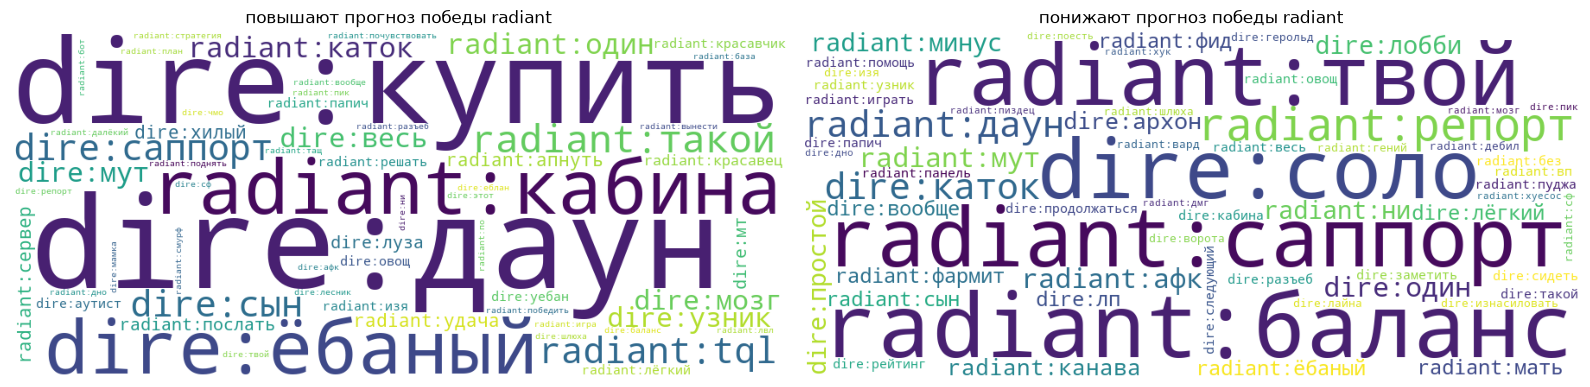

,term,weight
4290,radiant:баланс,-1.196222
5425,radiant:твой,-1.058520
5288,radiant:саппорт,-1.010892
11015,dire:соло,-1.001478
5253,radiant:репорт,-0.976367
4494,radiant:даун,-0.969707
10377,dire:каток,-0.968558
4279,radiant:афк,-0.954280
4892,radiant:мут,-0.933010
10679,dire:один,-0.928117


,term,weight
10149,dire:даун,1.029563
10416,dire:купить,0.997169
4705,radiant:кабина,0.985732
11344,dire:ёбаный,0.961264
5417,radiant:такой,0.947340
10948,dire:саппорт,0.941488
3777,radiant:tql,0.926582
11064,dire:сын,0.924016
5019,radiant:один,0.907574
4725,radiant:каток,0.905431


In [8]:
from wordcloud import WordCloud
text_names = np.concatenate([np.array([side + ':' + word for word in text_vectorizers[side].get_feature_names_out()]) for side in ['radiant', 'dire']])
text_weights = text_model.coef_[0, base_fit.shape[1]:]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, sign, title in zip(axes, [1, -1], ['повышают прогноз победы radiant', 'понижают прогноз победы radiant']):
    mask = sign * text_weights > 0
    frequencies = dict(zip(text_names[mask], np.abs(text_weights[mask])))
    cloud = WordCloud(random_state=SEED, width=900, height=400, background_color='white', collocations=False, max_words=60)
    ax.imshow(cloud.generate_from_frequencies(frequencies))
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()
word_weights = pd.DataFrame({'term': text_names, 'weight': text_weights})
display(word_weights.sort_values('weight').head(12))
display(word_weights.sort_values('weight', ascending=False).head(12))


## преимущество по золоту и опыту

используются точки минут 0–15. короткие ряды дополняются пропусками. значения по модулю больше 200 000 считаются повреждёнными: в золоте нашлось 143 таких точки.

radiant_gold_adv нереалистичных точек: 143
radiant_gold_adv строк: 767822 строк с пропусками: 529804 диапазон: -35580.0 123692.0


radiant_exp_adv нереалистичных точек: 0
radiant_exp_adv строк: 767822 строк с пропусками: 529783 диапазон: -32400.0 66705.0


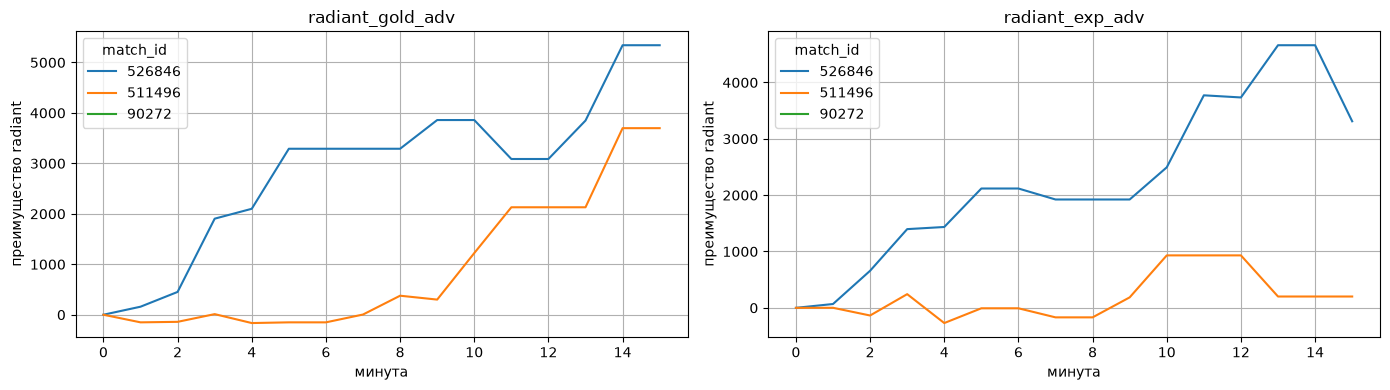

In [9]:
adv_raw = pd.read_csv(data_dir / 'dota_adv.csv')
assert not adv_raw['match_id'].duplicated().any()
adv_columns = ['radiant_gold_adv', 'radiant_exp_adv']

def parse_adv(value):
    if pd.isna(value):
        return np.full(16, np.nan)
    text = str(value).strip()
    if not (text.startswith('[') and text.endswith(']')):
        return np.full(16, np.nan)
    array = np.fromstring(text[1:-1].replace(',', ' '), sep=' ')
    output = np.full(16, np.nan)
    output[:min(16, len(array))] = array[:16]
    output[~np.isfinite(output)] = np.nan
    return output
adv = pd.DataFrame({'match_id': adv_raw['match_id']})
for column in adv_columns:
    adv[column] = adv_raw[column].map(parse_adv)
    matrix = np.vstack(adv[column])
    invalid = np.abs(matrix) > 200000
    print(column, 'нереалистичных точек:', invalid.sum())
    matrix[invalid] = np.nan
    adv[column] = list(matrix)
    print(column, 'строк:', len(matrix), 'строк с пропусками:', np.isnan(matrix).any(axis=1).sum(), 'диапазон:', np.nanmin(matrix), np.nanmax(matrix))
    assert matrix.shape[1] == 16
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, column in zip(axes, adv_columns):
    for row in range(3):
        ax.plot(np.arange(16), adv[column].iloc[row], label=str(adv['match_id'].iloc[row]))
    ax.set(title=column, xlabel='минута', ylabel='преимущество radiant')
    ax.legend(title='match_id')
plt.tight_layout()
plt.show()


### простые статистики

считаются среднее, разброс, минимум, максимум и средние положительной и отрицательной части. добавляется доля пропусков. заполнение и масштабирование обучаются только на train.

In [10]:
adv_stats = pd.DataFrame(index=pd.Index(adv['match_id'], name='match_id'))
for column in adv_columns:
    matrix = np.vstack(adv[column])
    values = pd.DataFrame(matrix)
    for statistic in ['mean', 'std', 'min', 'max']:
        adv_stats[column + '_' + statistic] = values.agg(statistic, axis=1).to_numpy()
    adv_stats[column + '_radiant_mean'] = values.clip(lower=0).mean(axis=1).to_numpy()
    adv_stats[column + '_dire_mean'] = (-values.clip(upper=0)).mean(axis=1).to_numpy()
    adv_stats[column + '_missing'] = values.isna().mean(axis=1).to_numpy()

def register_numeric_group(name, table):
    assert table.index.is_unique
    transformer = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])
    train_values = table.reindex(fit_clean['match_id'])
    valid_values = table.reindex(valid_clean['match_id'])
    feature_groups[name] = {'train': sparse.csr_matrix(transformer.fit_transform(train_values)), 'valid': sparse.csr_matrix(transformer.transform(valid_values)), 'transformer': transformer}
    feature_tables[name] = table
    return transformer
register_numeric_group('adv_stats', adv_stats)
evaluate_features('adv_stats', ('adv_stats',))
evaluate_features('adv_stats_text', ('adv_stats', 'text'), C=best_text_C)


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,adv_stats,[adv_stats],1.0,liblinear,500,0.398343,0.396284,0.085276,8.031999,171


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,adv_stats_text,"[adv_stats, text]",0.1,liblinear,500,0.419417,0.411786,0.100778,32.487184,11521


0.4117856365719652

### тренды

при одинаковом среднем команда может терять или набирать преимущество. считаются наклон, уровень и r² линейного тренда. отдельно проверяется разница крайних точек.

In [11]:
class TrendTransformer(BaseEstimator, TransformerMixin):

    def __init__(self, columns, method='ols', start=0, stop=16):
        self.columns = columns
        self.method = method
        self.start = start
        self.stop = stop

    def fit(self, X, y=None):
        if self.method not in ['ols', 'delta']:
            raise ValueError('method должен быть ols или delta')
        return self

    def transform(self, X):
        output = {}
        for column in self.columns:
            values = np.vstack(X[column])[:, self.start:self.stop]
            time_axis = np.arange(self.start, self.stop, dtype=float)
            valid = np.isfinite(values)
            count = valid.sum(axis=1)
            safe_count = np.maximum(count, 1)
            x_mean = (valid * time_axis).sum(axis=1) / safe_count
            y_mean = np.nansum(values, axis=1) / safe_count
            centered_x = time_axis[None, :] - x_mean[:, None]
            centered_y = np.where(valid, values - y_mean[:, None], 0)
            denominator = (valid * centered_x ** 2).sum(axis=1)
            covariance = (centered_x * centered_y).sum(axis=1)
            slope = np.divide(covariance, denominator, out=np.zeros(len(values)), where=denominator > 0)
            if self.method == 'delta':
                slope = (values[:, -1] - values[:, 0]) / max(len(time_axis) - 1, 1)
            intercept = y_mean - slope * x_mean
            residual = np.where(valid, values - (intercept[:, None] + slope[:, None] * time_axis), 0)
            total = (centered_y ** 2).sum(axis=1)
            residual_sum = (residual ** 2).sum(axis=1)
            r2 = np.divide(residual_sum, total, out=np.zeros(len(values)), where=total > 0)
            r2 = 1 - r2
            r2[(total == 0) & (residual_sum > 0)] = 0
            for label, data in [('slope', slope), ('intercept', intercept), ('r2', r2)]:
                data[count < 2] = np.nan
                output[column + '_' + label] = data
        return pd.DataFrame(output, index=X.index)
trend_ols = TrendTransformer(adv_columns, method='ols').fit_transform(adv)
trend_delta = TrendTransformer(adv_columns, method='delta').fit_transform(adv)
display(trend_ols.head())
example = pd.DataFrame({column: [2 * np.arange(16) + 3] for column in adv_columns})
check = TrendTransformer(adv_columns).fit_transform(example)
np.testing.assert_allclose(check.filter(like='slope'), 2)
np.testing.assert_allclose(check.filter(like='intercept'), 3)
np.testing.assert_allclose(check.filter(like='r2'), 1)


,radiant_gold_adv_slope,radiant_gold_adv_intercept,radiant_gold_adv_r2,radiant_exp_adv_slope,radiant_exp_adv_intercept,radiant_exp_adv_r2
0,304.388235,604.588235,0.810015,282.491176,143.566176,0.863183
1,256.185294,-987.514706,0.773514,42.938235,-130.411765,0.263800
2,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN


### последние минуты

добавляется тренд минут 10–15: он может отражать недавний перелом в игре.

In [12]:
trend_features = trend_ols.copy()
trend_features.index = pd.Index(adv['match_id'], name='match_id')
late = TrendTransformer(adv_columns, start=10, stop=16).fit_transform(adv)
late.index = trend_features.index
trend_features = trend_features.join(late.add_suffix('_late'))
register_numeric_group('trend', trend_features)
evaluate_features('trend_only_added', ('trend',))
evaluate_features('adv_stats_trend', ('adv_stats', 'trend'))


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,trend_only_added,[trend],1.0,liblinear,500,0.400375,0.398183,0.087176,28.040138,169


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,adv_stats_trend,"[adv_stats, trend]",1.0,liblinear,500,0.402383,0.400708,0.0897,44.012924,195


0.4007075695934519

### интервалы и окна

последнее преимущество разбивается на квантили. статистики считаются в трёх временных окнах. одинаковые границы квантилей объединяются из-за большого числа пропусков.

In [13]:
from sklearn.preprocessing import KBinsDiscretizer
adv_last = pd.DataFrame({column + '_last': np.vstack(adv[column])[:, -1] for column in adv_columns}, index=pd.Index(adv['match_id'], name='match_id'))
bin_encoder = Pipeline([('impute', SimpleImputer(strategy='median')), ('bins', KBinsDiscretizer(n_bins=8, encode='onehot', strategy='quantile', subsample=None, random_state=SEED))])
feature_groups['adv_bins'] = {'train': bin_encoder.fit_transform(adv_last.reindex(fit_clean['match_id'])), 'valid': bin_encoder.transform(adv_last.reindex(valid_clean['match_id']))}
feature_tables['adv_bins'] = adv_last
window_features = pd.DataFrame(index=adv_last.index)
for column in adv_columns:
    values = pd.DataFrame(np.vstack(adv[column]))
    for label, start, stop in [('early', 0, 5), ('middle', 5, 10), ('late', 10, 16)]:
        window = values.iloc[:, start:stop]
        window_features[column + '_' + label + '_mean'] = window.mean(axis=1).to_numpy()
        window_features[column + '_' + label + '_std'] = window.std(axis=1).to_numpy()
register_numeric_group('adv_windows', window_features)
evaluate_features('adv_bins', ('adv_bins',))
evaluate_features('adv_windows', ('adv_windows',))
evaluate_features('adv_all', ('adv_stats', 'trend', 'adv_bins', 'adv_windows'))


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,adv_bins,[adv_bins],1.0,liblinear,500,0.387318,0.382609,0.071601,3.086774,153


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,adv_windows,[adv_windows],1.0,liblinear,500,0.395754,0.395587,0.084579,5.867235,169


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,adv_all,"[adv_stats, trend, adv_bins, adv_windows]",1.0,liblinear,500,0.404236,0.401871,0.090863,27.295994,227


0.40187072667790025

## общий pipeline

преобразования и модель объединяются в общий pipeline. дополнительные таблицы сохраняются вместе с ней. для новых матчей нужно добавить их составы, чат и ряды. проверяется совпадение с отдельными блоками.

сравниваются gini общего pipeline и отдельных блоков. проверка ниже должна подтвердить совпадение.

In [14]:
from sklearn.base import clone
import cloudpickle

def calendar_features(frame):
    frame = frame.copy()
    date = pd.to_datetime(frame['date'])
    frame['date'] = date
    for label, values, period in [('day', date.dt.day - 1, date.dt.days_in_month), ('weekday', date.dt.dayofweek, 7), ('month', date.dt.month - 1, 12)]:
        frame[label + '_sin'] = np.sin(2 * np.pi * values / period)
        frame[label + '_cos'] = np.cos(2 * np.pi * values / period)
    frame['weekend'] = (date.dt.dayofweek >= 5).astype(int)
    return frame

class DotaPipeline(BaseEstimator):

    def __init__(self, groups=(), C=1.0, max_iter=500):
        self.groups = groups
        self.C = C
        self.max_iter = max_iter

    def _hero_features(self, frame):
        positions = self.hero_encoder_.match_index_.get_indexer(frame['match_id'])
        known = positions >= 0
        result = sparse.csr_matrix((len(frame), len(self.hero_encoder_.hero_index_)))
        if known.all():
            return self.hero_encoder_.matrix_[positions]
        valid_rows = np.flatnonzero(known)
        if len(valid_rows):
            present = self.hero_encoder_.matrix_[positions[known]].tocoo()
            result = sparse.csr_matrix((present.data, (valid_rows[present.row], present.col)), shape=result.shape)
        return result

    def _build_features(self, frame, fitting=False):
        frame = calendar_features(frame)
        if fitting:
            tabular = self.tabular_.fit_transform(frame)
        else:
            tabular = self.tabular_.transform(frame)
        blocks = [self._hero_features(frame), sparse.csr_matrix(tabular)]
        for group in self.groups:
            if group == 'text':
                chat_rows = self.chat_.reindex(frame['match_id']).fillna('')
                for side in ['radiant', 'dire']:
                    values = chat_rows[side + '_chat_clean']
                    vectorizer = self.text_vectorizers_[side]
                    transformed = vectorizer.fit_transform(values) if fitting else vectorizer.transform(values)
                    blocks.append(transformed)
            else:
                values = self.tables_[group].reindex(frame['match_id'])
                transformer = self.transformers_[group]
                transformed = transformer.fit_transform(values) if fitting else transformer.transform(values)
                blocks.append(sparse.csr_matrix(transformed))
        return sparse.hstack(blocks, format='csr')

    def fit(self, X, y):
        self.hero_encoder_ = hero_encoder
        self.tabular_ = make_model(use_dates=True, mmr='log').named_steps['features']
        self.tables_ = {group: feature_tables[group] for group in self.groups if group != 'text'}
        self.transformers_ = {}
        self.text_vectorizers_ = {}
        if 'text' in self.groups:
            self.chat_ = chat_index[['radiant_chat_clean', 'dire_chat_clean']]
            for side in ['radiant', 'dire']:
                self.text_vectorizers_[side] = clone(text_vectorizers[side])
        for group in self.tables_:
            if group == 'adv_bins':
                self.transformers_[group] = clone(bin_encoder)
            else:
                self.transformers_[group] = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])
        features = self._build_features(X, fitting=True)
        self.model_ = LogisticRegression(C=self.C, solver='liblinear', max_iter=self.max_iter, random_state=SEED)
        self.model_.fit(features, y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(self._build_features(X))

def run_pipeline(train_data, test_data, groups, C=1.0, output_dir=OUTPUT):
    pipeline = DotaPipeline(groups=tuple(groups), C=C)
    pipeline.fit(train_data, train_data['radiant_win'])
    predictions = pipeline.predict_proba(test_data)[:, 1]
    submission = pd.DataFrame({'ID': test_data['match_id'], 'Value': predictions})
    assert len(submission) == len(test_data)
    assert submission['ID'].is_unique
    assert np.isfinite(predictions).all() and submission['Value'].between(0, 1).all()
    submission.to_csv(output_dir / 'submission_advanced.csv', index=False)
    with open(output_dir / 'dota_advanced_pipeline.pkl', 'wb') as file:
        cloudpickle.dump(pipeline, file)
    return (pipeline, submission)
check_groups = ('adv_stats', 'trend')
pipeline_check = DotaPipeline(groups=check_groups, C=1.0).fit(fit_clean, fit_clean['radiant_win'])
pipeline_gini = gini(valid_clean['radiant_win'], pipeline_check.predict_proba(valid_clean)[:, 1])
print('gini единого pipeline:', pipeline_gini)
reference_gini = next((row['gini_valid'] for row in results if row['name'] == 'adv_stats_trend'))
np.testing.assert_allclose(pipeline_gini, reference_gini, atol=1e-08)


gini единого pipeline: 0.4007075695934519


### журнал экспериментов

группы признаков, настройки и метрики сохраняются в csv и sqlite.

In [15]:
import sqlite3

def save_registry():
    registry = pd.DataFrame(results).copy()
    registry['groups'] = registry['groups'].map(json.dumps)
    registry['seed'] = SEED
    registry['validation_start'] = str(cutoff.date())
    registry['validation_end'] = str(valid_clean['date'].max().date())
    registry['source'] = 'data/raw'
    assert registry['run_id'].is_unique
    registry.to_csv(OUTPUT / 'experiment_registry.csv', index=False)
    with sqlite3.connect(OUTPUT / 'experiments.sqlite') as connection:
        registry.to_sql('experiments', connection, if_exists='replace', index=False)
        connection.execute('create unique index run_id_unique on experiments(run_id)')
    return registry
registry = save_registry()
display(registry[['run_id', 'name', 'groups', 'C', 'gini_valid', 'delta_baseline']].round(6))


,run_id,name,groups,C,gini_valid,delta_baseline
0,7906bc30c9b7496aa1682a58f1df904f,baseline,[],8.301092,0.311008,0.000000
1,0485345893d54b869d87c7392d2de707,text_C_0.01,"[""text""]",0.010000,0.317118,0.006110
2,ba4ae25fca514f06aefaf9d4549b0378,text_C_0.1,"[""text""]",0.100000,0.331947,0.020939
3,dd704dede54b4cf9a5009a46dd9e4ee2,adv_stats,"[""adv_stats""]",1.000000,0.396284,0.085276
4,b6f260b82b784a189a3af35dc008479a,adv_stats_text,"[""adv_stats"", ""text""]",0.100000,0.411786,0.100778
5,4dbfc9d8e00d448581cb6f627565c4d0,trend_only_added,"[""trend""]",1.000000,0.398183,0.087176
6,4f9191a632df40bc9e8fde4f44dfa94c,adv_stats_trend,"[""adv_stats"", ""trend""]",1.000000,0.400708,0.089700
7,e723a4375c5a4e27bc7467d2de4e3397,adv_bins,"[""adv_bins""]",1.000000,0.382609,0.071601
8,eafd75374267471b826408c527db0a85,adv_windows,"[""adv_windows""]",1.000000,0.395587,0.084579
9,edc5c8252d624d18a8ac0583ba868ce1,adv_all,"[""adv_stats"", ""trend"", ""adv_bins"", ""adv_windows""]",1.000000,0.401871,0.090863


### cpu и gpu

необязательный эксперимент на одинаковых 100 000 матчей. на kaggle t4 качество было близким, но cpu оказался быстрее. разные solver и форматы матриц не позволяют считать это чистым сравнением железа. локально без rapids этот шаг пропускается.

In [16]:
gpu_status = 'не выполнен'
try:
    import cupy as cp
    from cuml.linear_model import LogisticRegression as GpuLogisticRegression
    if cp.cuda.runtime.getDeviceCount() == 0:
        raise RuntimeError('gpu не выделен сессии')
    rng = np.random.default_rng(SEED)
    positions = rng.choice(len(fit_clean), size=min(100000, len(fit_clean)), replace=False)
    gpu_X_train = cp.asarray(base_fit[positions].toarray(), dtype=cp.float32)
    gpu_y_train = cp.asarray(fit_clean['radiant_win'].to_numpy()[positions], dtype=cp.int32)
    gpu_X_valid = cp.asarray(base_valid.toarray(), dtype=cp.float32)
    gpu_model = GpuLogisticRegression(C=BASE_PARAMS['C'], max_iter=500)
    cp.cuda.Stream.null.synchronize()
    started = time.perf_counter()
    gpu_model.fit(gpu_X_train, gpu_y_train)
    gpu_predictions = cp.asnumpy(gpu_model.predict_proba(gpu_X_valid))[:, 1]
    cp.cuda.Stream.null.synchronize()
    elapsed = time.perf_counter() - started
    gpu_gini = gini(valid_clean['radiant_win'], gpu_predictions)
    cpu_model = LogisticRegression(C=BASE_PARAMS['C'], solver='liblinear', max_iter=500)
    cpu_started = time.perf_counter()
    cpu_model.fit(base_fit[positions], fit_clean['radiant_win'].iloc[positions])
    cpu_predictions = cpu_model.predict_proba(base_valid)[:, 1]
    cpu_elapsed = time.perf_counter() - cpu_started
    display(pd.DataFrame([{'backend': 'cuml gpu', 'gini_valid': gpu_gini, 'seconds_fit_predict': elapsed}, {'backend': 'sklearn cpu', 'gini_valid': gini(valid_clean['radiant_win'], cpu_predictions), 'seconds_fit_predict': cpu_elapsed}]))
    gpu_status = 'выполнен'
    del gpu_X_train, gpu_X_valid, gpu_y_train, gpu_model
    cp.get_default_memory_pool().free_all_blocks()
except (ImportError, RuntimeError) as error:
    print('cuml эксперимент недоступен в текущей среде:', error)
print('gpu эксперимент:', gpu_status)


cuml эксперимент недоступен в текущей среде: No module named 'cupy'
gpu эксперимент: не выполнен


### ещё несколько признаков

проверяются signed log последнего преимущества, доля лидерства, число смен лидера и изменение за последние пять минут. по отдельности полезный признак может почти ничего не добавить к уже сильной модели.

In [17]:
llm_features = pd.DataFrame(index=pd.Index(adv['match_id'], name='match_id'))
for column in adv_columns:
    values = pd.DataFrame(np.vstack(adv[column]))
    last = values.iloc[:, -1]
    llm_features[column + '_last_signed_log'] = (np.sign(last) * np.log1p(np.abs(last))).to_numpy()
    llm_features[column + '_lead_share'] = values.gt(0).where(values.notna()).mean(axis=1).to_numpy()
    signs = np.sign(values)
    changes = signs.iloc[:, 1:].to_numpy() != signs.iloc[:, :-1].to_numpy()
    valid_pair = values.iloc[:, 1:].notna().to_numpy() & values.iloc[:, :-1].notna().to_numpy()
    llm_features[column + '_lead_changes'] = (changes & valid_pair).sum(axis=1)
    late_delta = values.iloc[:, -1] - values.iloc[:, 10]
    llm_features[column + '_late_delta_signed_log'] = (np.sign(late_delta) * np.log1p(np.abs(late_delta))).to_numpy()
register_numeric_group('llm', llm_features)
evaluate_features('llm_added', ('llm',))
evaluate_features('adv_all_llm', ('adv_stats', 'trend', 'adv_bins', 'adv_windows', 'llm'))


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,llm_added,[llm],1.0,liblinear,500,0.3951,0.391283,0.080275,4.914054,159


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,adv_all_llm,"[adv_stats, trend, adv_bins, adv_windows, llm]",1.0,liblinear,500,0.404657,0.402562,0.091555,45.430869,241


0.40256243725791085

## отбор и итоговая модель

на каждом шаге добавляется лучшая группа по ноябрьскому gini. бюджет — три группы поверх baseline, минимальный прирост — 0,0001. это ограниченный поиск, а не проверка всех сочетаний.

сохранённый pipeline загружается, его прогнозы сравниваются с исходной моделью.

In [18]:
candidates = ['adv_stats', 'trend', 'adv_bins', 'adv_windows', 'llm', 'text']
MAX_GROUPS = 3
selected = []
best_score = evaluate_features('selection_start', (), C=0.1)
selection_history = []
while candidates and len(selected) < MAX_GROUPS:
    proposals = []
    for candidate in candidates:
        groups = tuple(selected + [candidate])
        name = 'select_' + '_'.join(groups)
        previous = [row for row in results if sorted(row['groups']) == sorted(groups) and row['C'] == 0.1]
        score = previous[-1]['gini_valid'] if previous else evaluate_features(name, groups, C=0.1)
        proposals.append((score, candidate))
    score, chosen = max(proposals)
    if score <= best_score + 0.0001:
        break
    selected.append(chosen)
    candidates.remove(chosen)
    best_score = score
    selection_history.append({'step': len(selected), 'added': chosen, 'gini_valid': score})
display(pd.DataFrame(selection_history))
print('выбранные группы:', selected)
print('gini после отбора:', best_score)
print('прирост относительно baseline:', best_score - base_gini)
final_pipeline, submission = run_pipeline(train_clean, test, groups=selected, C=0.1)
with open(OUTPUT / 'dota_advanced_pipeline.pkl', 'rb') as file:
    restored_pipeline = cloudpickle.load(file)
check_rows = test.head(20)
np.testing.assert_allclose(final_pipeline.predict_proba(check_rows), restored_pipeline.predict_proba(check_rows))
save_registry()
with open(OUTPUT / 'advanced_config.json', 'w') as file:
    json.dump({'groups': selected, 'max_groups': MAX_GROUPS, 'C': 0.1, 'solver': 'liblinear', 'max_iter': 500, 'validation_gini': best_score, 'baseline_gini': base_gini, 'gpu_status': gpu_status}, file, indent=2)
display(submission.head())
print('csv:', submission.shape)
print('артефакты:', [path.name for path in OUTPUT.iterdir() if path.is_file()])


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,selection_start,[],0.1,liblinear,500,0.313931,0.311003,-0.000005,2.375848,145


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,select_adv_stats,[adv_stats],0.1,liblinear,500,0.398342,0.396278,0.08527,9.880861,171


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,select_trend,[trend],0.1,liblinear,500,0.400282,0.398075,0.087067,18.507352,169


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,select_adv_bins,[adv_bins],0.1,liblinear,500,0.387318,0.382604,0.071597,3.330737,153


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,select_adv_windows,[adv_windows],0.1,liblinear,500,0.395753,0.395583,0.084576,7.887872,169


,name,groups,C,solver,max_iter,gini_train,gini_valid,delta_baseline,seconds,features
0,select_llm,[llm],0.1,liblinear,500,0.395098,0.391275,0.080268,5.386685,159


... (9 outputs left out)

,step,added,gini_valid
0,1,trend,0.398075
1,2,text,0.413538
2,3,adv_windows,0.417358


выбранные группы: ['trend', 'text', 'adv_windows']
gini после отбора: 0.4173577692352666
прирост относительно baseline: 0.10635001102145991


,ID,Value
0,8,0.443946
1,29,0.625993
2,34,0.656939
3,36,0.477368
4,61,0.605873


csv: (59748, 2)артефакты: ['advanced_config.json', 'experiments.sqlite', 'submission_advanced.csv', 'experiment_registry.csv', 'dota_advanced_pipeline.pkl']


## выводы

чат и динамика преимущества дополняют составы команд. больше признаков не всегда лучше: часть групп повторяет уже доступную информацию.

отбор сделан на том же ноябре, где измеряется качество. это может завысить результат. следующий шаг — несколько временных разбиений и отдельный период для финальной оценки.